Для решения задачи кластеризации возьмем из исходного датасета первой промежуточной аттестации непрерывные физические параметры телеметрии оборудования в моменты его активной работы.

Переменные для кластеризации (X):
1. power_avg потребляемая мощность
2. rpm_avg скорость вращения
3. temp_avg средняя температура станка
4. vib_avg средняя вибрация

ТАк мы разделим работу оборудования на однородные режимы, определим наиболее влияющие на износ оборования и сопоставим полученные группы с целевой бинарной переменной failure_next_24h.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

In [7]:
# загрузим данные, определим таргет и фичи

df = pd.read_csv("../v_machine_features_predictive.csv", parse_dates=['snapshot_time'])

cluster_features = ['power_avg', 'rpm_avg', 'temp_avg', 'vib_avg']
target_clf = 'failure_next_24h'

df_cluster = df[cluster_features + [target_clf]].dropna().reset_index(drop=True)
print(f"Размер выборки для кластеризации: {df_cluster.shape[0]} строк.")

# масштабирую признаки
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_cluster[cluster_features])
df_scaled = pd.DataFrame(X_scaled, columns=cluster_features)

df_scaled.info()


Размер выборки для кластеризации: 12183 строк.
<class 'pandas.DataFrame'>
RangeIndex: 12183 entries, 0 to 12182
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   power_avg  12183 non-null  float64
 1   rpm_avg    12183 non-null  float64
 2   temp_avg   12183 non-null  float64
 3   vib_avg    12183 non-null  float64
dtypes: float64(4)
memory usage: 380.8 KB


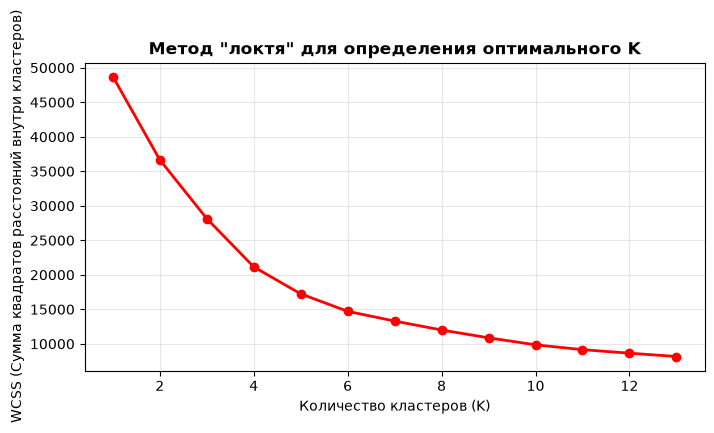

--- Оценка качества разделения (Silhouette Score) ---
Silhouette Score для K=2: 0.3811
Silhouette Score для K=3: 0.4040
Silhouette Score для K=4: 0.4272
Silhouette Score для K=5: 0.4162
Silhouette Score для K=6: 0.3644


In [14]:
# Подберем оптмальное число кластеров 
wcss = []
K_range = range(1, 14)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Визуализируем метода "локтя"
plt.figure(figsize=(8, 4))
plt.plot(K_range, wcss, 'ro-', linewidth=2)
plt.title('Метод "локтя" для определения оптимального K', fontsize=12, fontweight='bold')
plt.xlabel('Количество кластеров (K)')
plt.ylabel('WCSS (Сумма квадратов расстояний внутри кластеров)')
plt.grid(True, alpha=0.3)
plt.show()

# Оценка Silhouette Score для K = 2, 3, 4, 5, 6 
print("--- Оценка качества разделения (Silhouette Score) ---")
for k in [2, 3, 4, 5, 6]:
    labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_scaled[:5000])
    score = silhouette_score(X_scaled[:5000], labels)
    print(f"Silhouette Score для K={k}: {score:.4f}")

График с 1 до 4 падает резко, почти прямолинейно. После 4 угол наклона заметно меняется, и после 5 выполаживается.
Примим за локоть число 4, то есть  оптимальным будет 4 кластера.

In [19]:
# обучим финальную модель K-Means

optimal_k = 4
kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)

# Присваиваем каждому наблюдению метку кластера (0, 1, 2 или 3)
df_cluster['kmeans_cluster'] = kmeans_final.fit_predict(X_scaled)

print(f"Распределение наблюдений по {optimal_k} кластерам (K-Means):")
print(df_cluster['kmeans_cluster'].value_counts().sort_index())



Распределение наблюдений по 4 кластерам (K-Means):
kmeans_cluster
0    6287
1    4372
2    1224
3     300
Name: count, dtype: int64


Для разделения на кастеры с помощью иерархической кластеризации воспользуемся методом Уорда и среднего расстояния

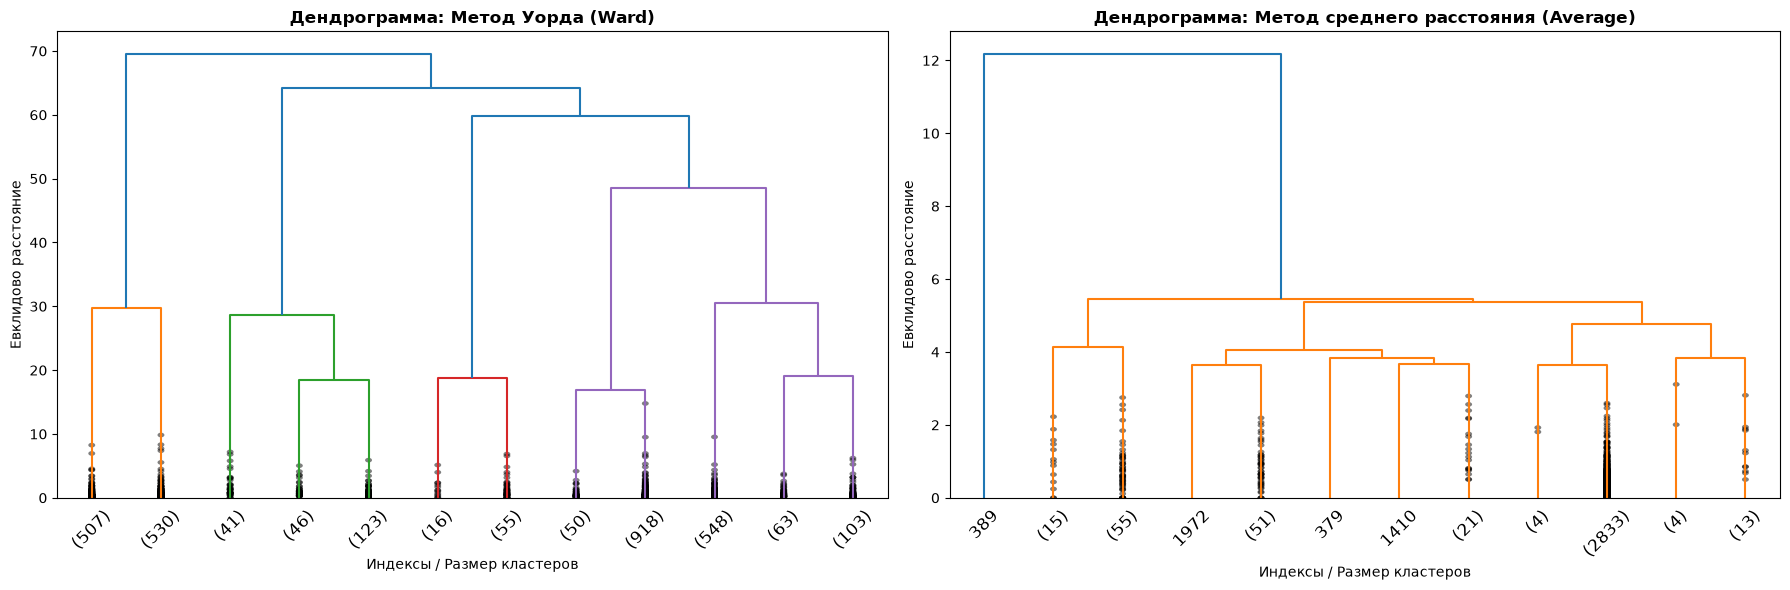

--- Сравнение размеров кластеров на подвыборке (3000 строк) ---
K-Means:
 {0: 1567, 1: 1061, 2: 307, 3: 65}
Иерархический (Ward):
 {1: 1037, 2: 210, 3: 71, 4: 1682}
Иерархический (Average):
 {1: 70, 2: 75, 3: 2854, 4: 1}


In [20]:
# Иерархическая кластеризация
# Берем случайную подвыборку в 3000 строк, чтобы не перегрузить память
np.random.seed(0)
sample_idx = np.random.choice(df_cluster.index, size=3000, replace=False)
X_sample_scaled = X_scaled[sample_idx]

fig, ax = plt.subplots(1, 2, figsize=(18, 6))

# 1. Метод Уорда
Z_ward = linkage(X_sample_scaled, method='ward')
dendrogram(Z_ward, ax=ax[0], truncate_mode='lastp', p=12, leaf_rotation=45, show_contracted=True)
ax[0].set_title('Дендрограмма: Метод Уорда (Ward)', fontsize=12, fontweight='bold')
ax[0].set_xlabel('Индексы / Размер кластеров')
ax[0].set_ylabel('Евклидово расстояние')

# 2. Метод среднего расстояния
Z_average = linkage(X_sample_scaled, method='average')
dendrogram(Z_average, ax=ax[1], truncate_mode='lastp', p=12, leaf_rotation=45, show_contracted=True)
ax[1].set_title('Дендрограмма: Метод среднего расстояния (Average)', fontsize=12, fontweight='bold')
ax[1].set_xlabel('Индексы / Размер кластеров')
ax[1].set_ylabel('Евклидово расстояние')

plt.tight_layout()
plt.show()

# Срезаем оба дерева на 4 кластера, чтобы сравнить их с K-Means
df_sample_comp = df_cluster.loc[sample_idx].copy()
df_sample_comp['hier_ward'] = fcluster(Z_ward, t=4, criterion='maxclust')
df_sample_comp['hier_average'] = fcluster(Z_average, t=4, criterion='maxclust')

print("--- Сравнение размеров кластеров на подвыборке (3000 строк) ---")
print("K-Means:\n", df_sample_comp['kmeans_cluster'].value_counts().sort_index().to_dict())
print("Иерархический (Ward):\n", df_sample_comp['hier_ward'].value_counts().sort_index().to_dict())
print("Иерархический (Average):\n", df_sample_comp['hier_average'].value_counts().sort_index().to_dict())


• Метод Уорда: Раскрасил дерево в четыре сбалансированные ветви (оранжевую, зеленую, красную и фиолетовую). Он старается делить данные на сопоставимые по объему рабочие режимы. По своей логике и распределению он максимально близок к алгоритму K-Means.
• Метод среднего расстояния: Почти все наблюдения он объединил в один  оранжевый кластер. Для задачи сегментации режимов работы завода этот метод не подходит, так как объединяет разные режимы в одну кучу.

--- Средние физические показатели оборудования по кластерам ---


,power_avg,rpm_avg,temp_avg,vib_avg
kmeans_cluster,,,,
0,0.637,2459.510,68.292,2.513
1,1.273,2457.533,68.303,2.511
2,0.802,2287.487,66.010,2.515
3,0.870,2463.702,68.517,4.016


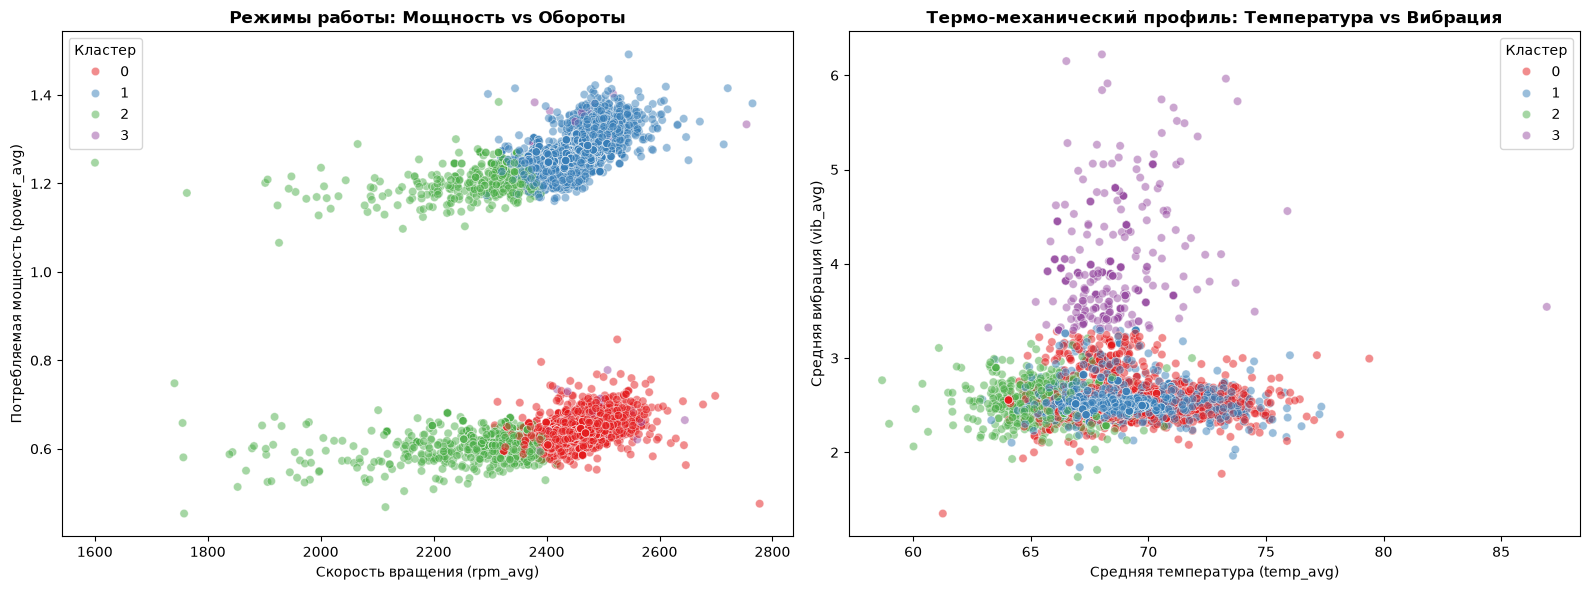


--- Связь кластеров с целевой переменной отказов (failure_next_24h) ---


failure_next_24h,0,1,All,Доля отказов в кластере (%)
kmeans_cluster,,,,
0,6192,95,6287,1.51
1,4320,52,4372,1.19
2,1187,37,1224,3.02
3,296,4,300,1.33
All,11995,188,12183,1.54


In [ ]:
# Визуализируем полученные результаты

# 1. Выводим средние физические показатели для каждого кластера K-Means
cluster_profile = df_cluster.groupby('kmeans_cluster')[cluster_features].mean()
print("--- Средние физические показатели оборудования по кластерам ---")
display(cluster_profile.round(3))

# 2. Строим визуализации различий кластеров
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# График А: Разделение по Мощности и Оборотам
sns.scatterplot(x='rpm_avg', y='power_avg', hue='kmeans_cluster', data=df_cluster, palette='Set1', alpha=0.5, ax=ax[0])
ax[0].set_title('Режимы работы: Мощность vs Обороты', fontsize=12, fontweight='bold')
ax[0].set_xlabel('Скорость вращения (rpm_avg)')
ax[0].set_ylabel('Потребляемая мощность (power_avg)')
ax[0].legend(title='Кластер')

# График Б: Разделение по Температуре и Вибрации
sns.scatterplot(x='temp_avg', y='vib_avg', hue='kmeans_cluster', data=df_cluster, palette='Set1', alpha=0.5, ax=ax[1])
ax[1].set_title('Термо-механический профиль: Температура vs Вибрация', fontsize=12, fontweight='bold')
ax[1].set_xlabel('Средняя температура (temp_avg)')
ax[1].set_ylabel('Средняя вибрация (vib_avg)')
ax[1].legend(title='Кластер')

plt.tight_layout()
plt.show()

# 3. проверяем концентрацию поломок в каждом кластере
print("\n--- Связь кластеров с целевой переменной отказов (failure_next_24h) ---")
cross_tab = pd.crosstab(df_cluster['kmeans_cluster'], df_cluster[target_clf], margins=True)
cross_tab['Доля отказов в кластере (%)'] = (cross_tab[1] / cross_tab['All']) * 100
display(cross_tab.round(2))


1. Кластер 0 (Красный, 6 287 наблюдений): «Штатный режим — Легкие станки»
	• Физика: Низкое энергопотребление (power_avg = 0.637), но высокие стабильные обороты (rpm_avg = 2459), нормальная температура (68.3°C) и штатная вибрация (2.51).
	• Бизнес-смысл: Основной объем работы легких станков (например, легких ЧПУ или роботов) на проектной скорости.

2. Кластер 1 (Синий, 4 372 наблюдения): «Штатный режим — Тяжелые станки»
	• Физика: Вдвое большее энергопотребление (power_avg = 1.273), те же высокие проектные обороты (2457), нормальная температура (68.3°C) и вибрация (2.51).
	• Бизнес-смысл: Стабильная, ритмичная работа тяжелых станков под нагрузкой.

3. Кластер 3 (Фиолетовый, 300 наблюдений): «Режим механической разбалансировки (Вибро-аномалия)»
	• Физика: При обычных оборотах и температуре, средний уровень вибрации здесь подскакивает почти в 2 раза (vib_avg = 4.016 против 2.51 в норме).
	• Бизнес-смысл: На правом графике этот кластер уходит вертикально вверх. Это явный признак износа подшипников, ослабления креплений или биения вала. Оборудование еще не сломалось, но требует внеплановой диагностики.

4. Кластер 2 (Зеленый, 1 224 наблюдения): «Переходный / Нестабильный режим (Зона риска)»
	• Физика: Просадка оборотов (rpm_avg = 2287), пониженная температура (66.0°C — станок не вышел на рабочую полку) и промежуточная мощность (0.802). На левом графике видно, что этот кластер объединяет левые «хвосты» обоих типов станков.
	• Бизнес-смысл: Режимы пуска, остановки, переналадки или «просадки» двигателя под сопротивлением.


• В штатных режимах (Кластеры 0 и 1) доля поломок минимальна и составляет 1.19% – 1.51% (ниже среднего по заводу в 1.54%).
• В Кластере 2 («Нестабильный / Переходный режим») концентрация отказов подскакивает до 3.02% — это в 2.5 раза выше, чем при стабильной работе.



Сравнение K-Means и Иерархической кластеризации:

• K-Means и иерархический метод Уорда показали высокое сходство: оба метода независимо друг от друга выделили те же самые 4 технологических профиля со схожими пропорциями.
• Метод среднего расстояния оказался неприменим для сегментации из-за чувствительности к выбросам он объединил 95% наблюдений в один гигантский кластер и выделил единичные аномалии в отдельные группы.